# Exploratory Data Analysis: NBA Team Stats

**Author:** Matthew Wissell

This notebook explores a data set with records of NBA team advanced statistics for each season between 2000 and 2025 to discover relationships between measures of team performance. Our intent is to assess whether some features in this data set can be used as weights for modeling player performance. We also endeavor to highlight the most relevant performance indicators of team success with that assumption that players which contribute to these indicators have greater value.

- Data loading and cleaning: importing data and making adjustments before further processing.
- Univariate analysis: reviewing features, their values, and distributions.
- Multivariate analysis: assessing correlations and other relationships between two or more features.
- Key insights: deriving insights from observations made.


In [1]:
# Package imports used in the following notebook cells.
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display
from scipy.stats import probplot
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestClassifier
from scipy import stats
import pandas as pd

## Data loading and initial view.
Before exploring feature values and their relationships, it's important to review the advanced statistics definitions from the original source, Basketball-Reference.com. One of the challenges with this data set is that a number of features are derived from others in the same set. An important part of this process is assessing which features may have merit for use in future models.

In [2]:
data_dictionary = pl.read_csv("data/data_dict.csv")

In [3]:
# Format and display feature definitions
pd.set_option('display.max_colwidth', None)
display(data_dictionary.to_pandas().style.set_properties(**{
    'text-align': 'left',
    'white-space': 'pre-wrap'
}).set_table_styles([{
    'selector': 'th',
    'props': [('text-align', 'left')]
}]))

,Term,Definition
0,PW,Pythagorean wins
1,PL,Pythagorean losses
2,MOV,Margin of victory
3,SOS,Strenght of schedule
4,SRS,Simple rating system; accounts of SOS
5,ORtg,Based on points scored per 100 possessions
6,DRtg,Based on points allowed per 100 possessions
7,NRtg,Based on point differential per 100 possessions
8,Pace,Possessions per 48 minutes
9,FTr,Number of FTA per FGA


Feature values are reviewed to assess completeness and inconsistencies. Missing values are only identified in the features related to arena and attendance metrics.

In [4]:
# Read the Team_00-25.csv file using Polars
df = pl.read_csv("data/Team_00-25.csv")
df.describe()

statistic,Rank,Team,Age,Win,Lose,PW,PL,MOV,SOS,SRS,ORtg,DRtg,NRtg,Pace,FTr,3PAr,TS%,eFG%_Offense_Four_Factors,TOV%_Offense_Four_Factors,ORB%_Offense_Four_Factors,FT/FGA_Offense_Four_Factors,eFG%_Defense_Four_Factors,TOV%_Defense_Four_Factors,DRB%_Defense_Four_Factors,FT/FGA_Defense_Four_Factors,Arena,Total Attendance,Avg_Home_Game_Attendance,Season,Playoffs
str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,str,f64
"""count""",746.0,"""746""",746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,746.0,"""746""",742.0,742.0,"""746""",746.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",4.0,4.0,"""0""",0.0
"""mean""",15.422252,null,26.608981,40.246649,40.246649,40.313673,40.179625,-0.00626,-0.000603,-0.007118,108.014879,108.012064,0.002815,94.426676,0.283214,0.276184,0.545555,0.505599,13.243566,25.619035,0.215639,0.505582,13.245576,74.366086,0.215728,null,683316.407008,16959.338275,null,0.536193
"""std""",8.618849,null,1.749466,12.254166,12.175926,11.979546,11.908935,4.618571,0.382966,4.494806,4.802156,4.598192,4.842885,4.085952,0.038677,0.092351,0.025716,0.02908,1.105735,3.151331,0.027986,0.027484,1.171227,2.674376,0.028611,null,149494.635708,3549.579309,null,null
"""min""",1.0,"""Atlanta Hawks""",22.1,7.0,9.0,7.0,14.0,-13.91,-0.95,-13.96,92.2,94.1,-15.2,86.2,0.194,0.101,0.469,0.428,9.9,17.9,0.143,0.433,10.3,67.7,0.145,"""ARCO Arena (II)""",5817.0,162.0,"""2000-01""",0.0
"""25%""",8.0,null,25.4,32.0,31.0,32.0,31.0,-3.08,-0.29,-3.07,104.6,104.8,-3.3,91.1,0.255,0.203,0.527,0.484,12.5,23.4,0.195,0.485,12.4,72.4,0.195,null,633153.0,15846.0,null,null
"""50%""",15.0,null,26.5,41.0,39.0,41.0,40.0,0.26,0.0,0.17,107.5,107.7,0.3,94.0,0.28,0.257,0.543,0.502,13.3,25.5,0.213,0.504,13.2,74.4,0.213,null,706165.0,17451.0,null,null
"""75%""",23.0,null,27.7,49.0,49.0,49.0,49.0,3.3,0.29,3.14,111.2,111.2,3.4,97.9,0.307,0.356,0.564,0.527,14.0,27.8,0.233,0.525,14.1,76.3,0.233,null,776336.0,18997.0,null,null
"""max""",30.0,"""Washington Wizards""",32.0,73.0,72.0,68.0,67.0,12.87,0.96,12.7,123.2,120.4,12.8,105.1,0.417,0.536,0.61,0.578,17.1,35.3,0.303,0.576,16.5,81.6,0.34,"""Wells Fargo Center""",913176.0,22273.0,"""2024-25""",1.0


Three features in the original data set relate to a team's home arena and attendance metrics. Although it's fair to assume there is a home court advantage, it's not clear how these features can be used to support player performance without additional data which may be beyond the scope of this project. As a result, these features are dropped. This also eliminates the only features with missing values.

In [5]:
# Drop specified columns
df = df.drop(['Arena', 'Total Attendance', 'Avg_Home_Game_Attendance'])
display(df.head(3))

Rank,Team,Age,Win,Lose,PW,PL,MOV,SOS,SRS,ORtg,DRtg,NRtg,Pace,FTr,3PAr,TS%,eFG%_Offense_Four_Factors,TOV%_Offense_Four_Factors,ORB%_Offense_Four_Factors,FT/FGA_Offense_Four_Factors,eFG%_Defense_Four_Factors,TOV%_Defense_Four_Factors,DRB%_Defense_Four_Factors,FT/FGA_Defense_Four_Factors,Season,Playoffs
i64,str,f64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,bool
1,"""Dallas Mavericks""",28.1,60,22,62,20,7.78,0.12,7.9,110.7,102.3,8.4,92.5,0.257,0.239,0.543,0.498,10.9,25.4,0.213,0.473,14.8,70.9,0.221,"""2002-03""",true
2,"""Sacramento Kings""",28.3,59,23,59,23,6.5,0.18,6.68,105.9,99.1,6.8,95.4,0.262,0.184,0.535,0.499,13.3,25.6,0.196,0.446,13.6,70.6,0.204,"""2002-03""",true
3,"""San Antonio Spurs""",28.4,60,22,57,25,5.41,0.23,5.65,105.6,99.7,5.9,90.0,0.348,0.202,0.541,0.497,15.1,28.8,0.253,0.453,14.2,71.3,0.199,"""2002-03""",true


Dataframe columns are also reordered, sorted, and renamed to aid in navigation, interpretation, and to simplify code used to refer to specific feature titles by column name.

In [6]:
# Reorder columns
df = df.select(
    ['Team', 'Season', 'Rank'] +
    [col for col in df.columns if col not in ['Team', 'Season', 'Rank']]
)

col_list = list(df.columns)
playoffs_idx = col_list.index('Playoffs')
age_idx = col_list.index('Age')
col_list[playoffs_idx], col_list[age_idx] = col_list[age_idx], col_list[playoffs_idx]
df = df.select(col_list)

df = df.rename({
    "eFG%_Offense_Four_Factors": "eFG%_O4",
    "TOV%_Offense_Four_Factors": "TOV%_O4",
    "ORB%_Offense_Four_Factors": "ORB%_O4",
    "FT/FGA_Offense_Four_Factors": "FT/FGA_O4",
    "eFG%_Defense_Four_Factors": "eFG%_D4",
    "TOV%_Defense_Four_Factors": "TOV%_D4",
    "DRB%_Defense_Four_Factors": "DRB%_D4",
    "FT/FGA_Defense_Four_Factors": "FT/FGA_D4"
})

# Sort DataFrame by Season and Team
df = df.sort(['Season', 'Team'])

display(df.head(5))

Team,Season,Rank,Playoffs,Win,Lose,PW,PL,MOV,SOS,SRS,ORtg,DRtg,NRtg,Pace,FTr,3PAr,TS%,eFG%_O4,TOV%_O4,ORB%_O4,FT/FGA_O4,eFG%_D4,TOV%_D4,DRB%_D4,FT/FGA_D4,Age
str,str,i64,bool,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Atlanta Hawks""","""2000-01""",25,false,25,57,26,56,-5.21,-0.34,-5.55,98.7,104.3,-5.6,91.9,0.272,0.14,0.5,0.456,15.5,28.9,0.206,0.472,13.8,70.8,0.249,26.1
"""Boston Celtics""","""2000-01""",20,false,36,46,35,47,-2.13,-0.26,-2.4,101.4,103.7,-2.3,92.6,0.338,0.252,0.521,0.473,14.7,25.3,0.25,0.493,16.0,72.7,0.256,25.9
"""Charlotte Hornets""","""2000-01""",13,true,46,36,48,34,2.1,-0.65,1.45,101.8,99.5,2.3,89.4,0.33,0.151,0.506,0.457,13.7,29.8,0.246,0.456,14.1,74.5,0.222,28.2
"""Chicago Bulls""","""2000-01""",29,false,15,67,16,66,-9.1,0.01,-9.09,97.2,107.3,-10.1,89.3,0.298,0.148,0.495,0.45,15.1,26.6,0.22,0.499,14.3,70.3,0.254,23.2
"""Cleveland Cavaliers""","""2000-01""",23,false,30,52,28,54,-4.24,-0.23,-4.48,100.3,104.9,-4.6,91.2,0.312,0.101,0.509,0.459,15.4,29.7,0.239,0.477,14.1,71.1,0.248,26.9


We also perform a cursory review of string data to validate that there are no errors in team or season representation.

In [7]:
# Display unique counts for Team and Season
print("Number of unique Teams:", df['Team'].n_unique())
print("Number of unique Seasons:", df['Season'].n_unique())

Number of unique Teams: 36
Number of unique Seasons: 25


In [8]:
# Display unique teams in alphabetical order
unique_teams = sorted(df['Team'].unique())
print("List of all teams:")
for team in unique_teams:
    print(team)

List of all teams:
Atlanta Hawks
Boston Celtics
Brooklyn Nets
Charlotte Bobcats
Charlotte Hornets
Chicago Bulls
Cleveland Cavaliers
Dallas Mavericks
Denver Nuggets
Detroit Pistons
Golden State Warriors
Houston Rockets
Indiana Pacers
Los Angeles Clippers
Los Angeles Lakers
Memphis Grizzlies
Miami Heat
Milwaukee Bucks
Minnesota Timberwolves
New Jersey Nets
New Orleans Hornets
New Orleans Pelicans
New Orleans/Oklahoma City Hornets
New York Knicks
Oklahoma City Thunder
Orlando Magic
Philadelphia 76ers
Phoenix Suns
Portland Trail Blazers
Sacramento Kings
San Antonio Spurs
Seattle SuperSonics
Toronto Raptors
Utah Jazz
Vancouver Grizzlies
Washington Wizards


**Insights:** The data set appears readily usable with numeric features describing team performance by season. This includes a number of statistical metrics used to summarize other features within the same data set. As a result, feature selection is a major focus of the following analysis.

 ## Univariate Analysis
 One of our team members, Rasheed Martin, put together a quick function which is used here to iterate through all numeric features to review their distributions using histograms, box plots, and QQ plots. Team, Season, Rank, and Playoff features are not included. Team and Season represent record identifiers, Rank is consistently evenly distributed, and Playoff is a boolean value.

In [9]:
def univariate_eda(df: pl.DataFrame, columns=None, bins=30):
    """
    Perform univariate analysis on specified numerical columns.
    If columns is None, all numeric columns will be analyzed.
    """
    if columns is None:
        columns = df.select(pl.exclude('Team', 'Season', 'Rank', 'Playoffs')).columns

    for col in columns:
        print(f"\n--- {col} ---")
        print(df[col].describe())
        print(f"Skewness: {df[col].skew():.2f}")
        print(f"Kurtosis: {df[col].kurtosis():.2f}")

        fig, axes = plt.subplots(1, 3, figsize=(18, 4))

        # Histogram + KDE
        sns.histplot(df[col], bins=bins, kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f"{col} Distribution")

        # Boxplot
        sns.boxplot(x=df[col], ax=axes[1], color='salmon')
        axes[1].set_title(f"{col} Boxplot")

        # QQ Plot
        probplot(df[col].drop_nulls(), dist="norm", plot=axes[2])
        axes[2].set_title(f"{col} QQ Plot")

        plt.tight_layout()
        plt.show()

In [ ]:
univariate_eda(df)

**Insights:** Most of the features are generally described with normal distributions with some variability in skewness between them. There are limited signs of outliers. Some features of note are 3PAr and Pace which are described with bimodal distributions. Given that this data set is technically a time series recording feature values by season, this is possibly an indicator that league behaviors related to these two features changed over time.

## Multivariate Analysis
Beginning with a correlation plot to preview bivariate feature relationships, we will then transition to a multivariate model to validate the most important features in defining unique team performance. Again, the intent is to aid in feature selection for future modeling.

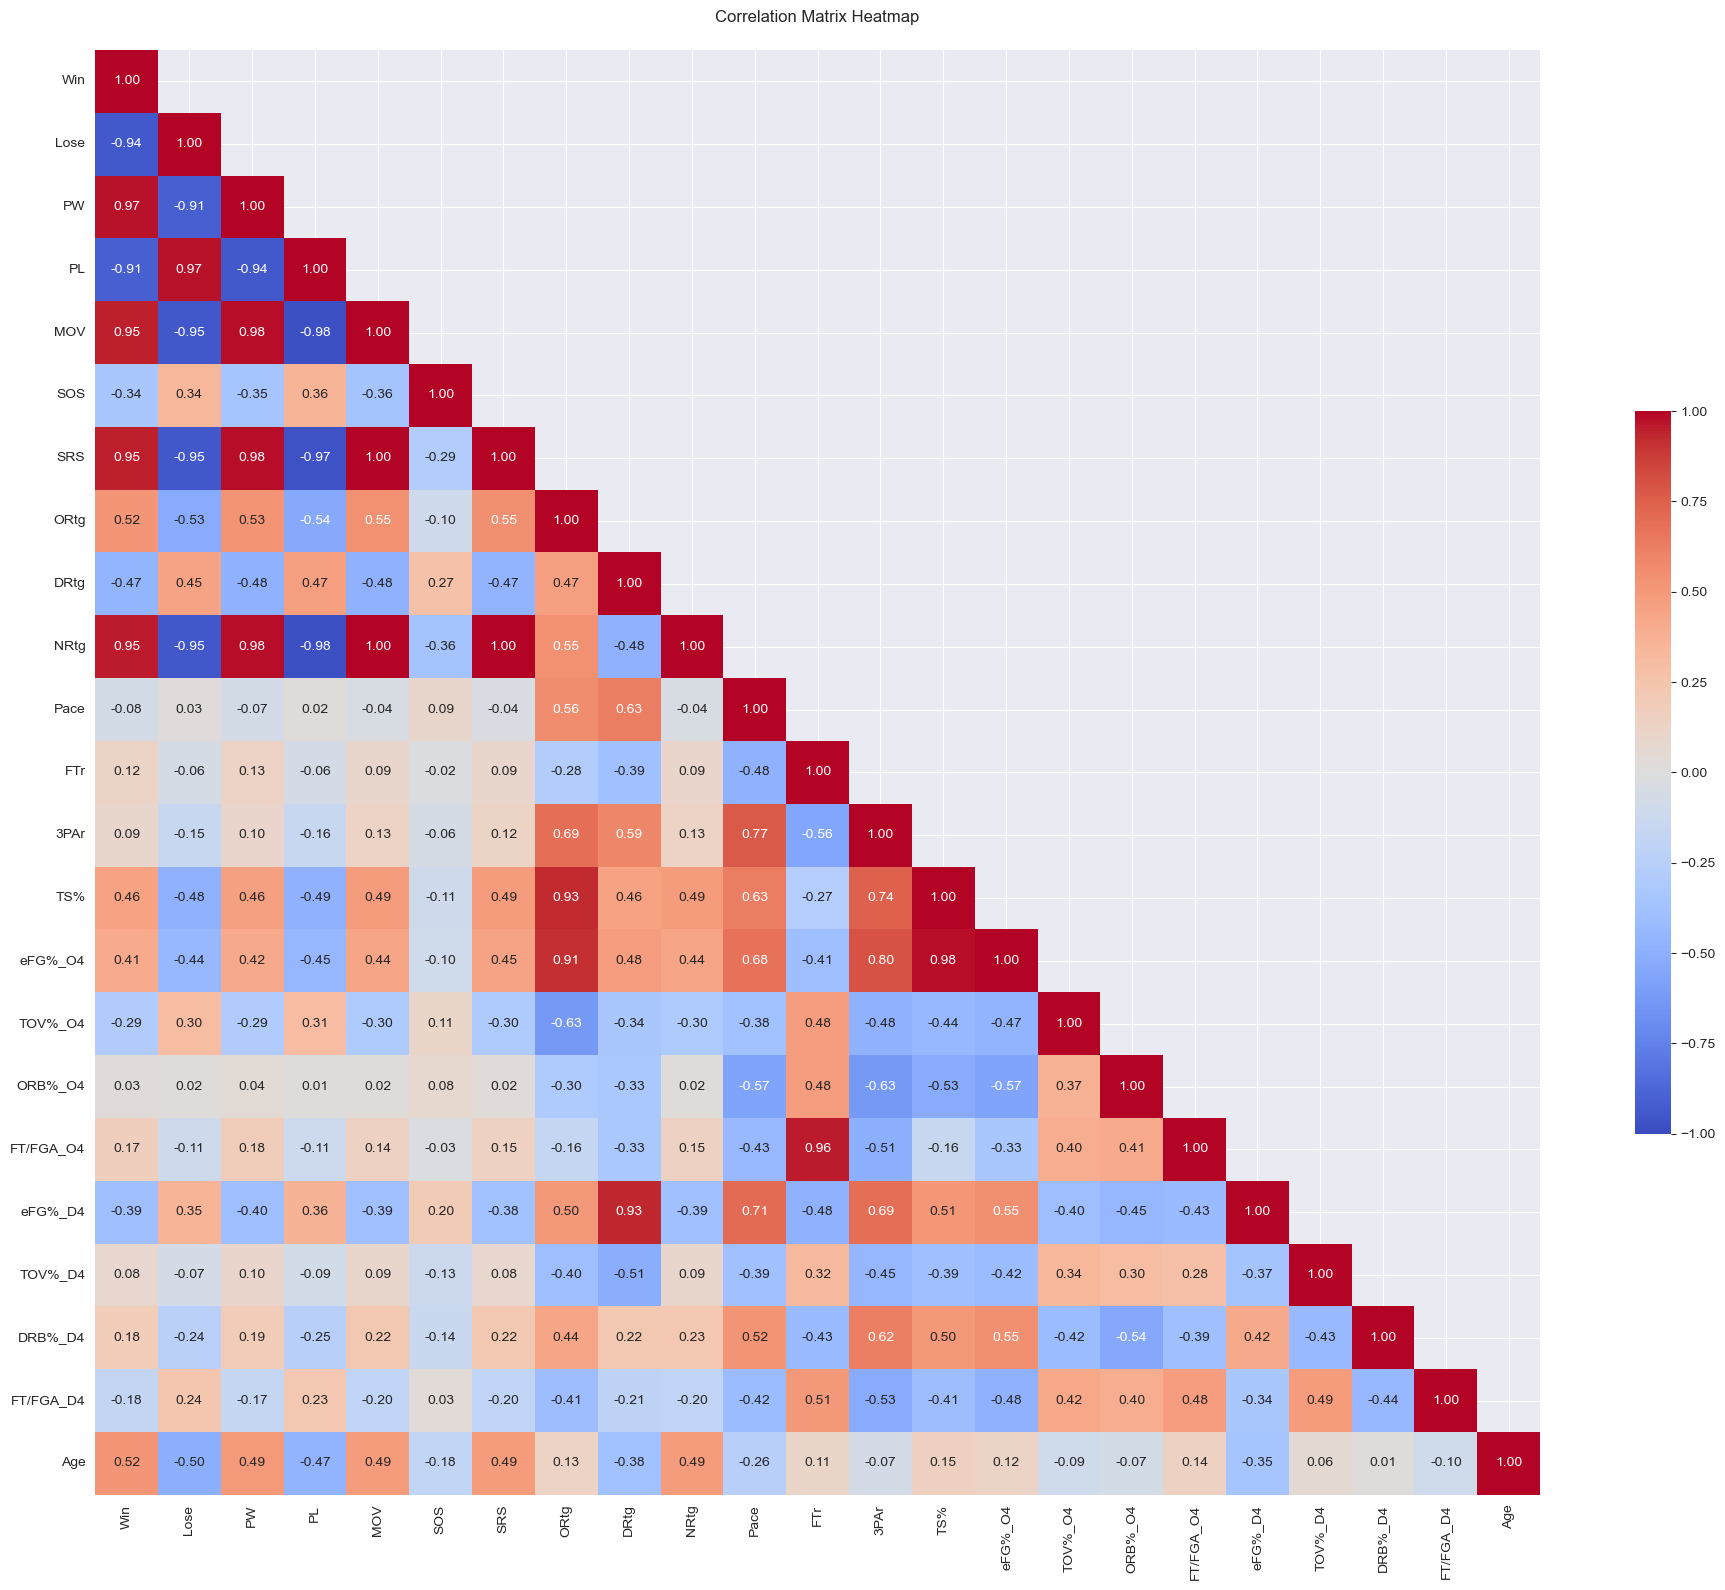

In [11]:
# Create correlation matrix
plt.figure(figsize=(20, 16))
corr_matrix = df.select(pl.exclude(['Team', 'Season', 'Rank', 'Playoffs'])).corr()

# Create heatmap
mask = np.triu(np.ones_like(corr_matrix), k=1)
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            xticklabels=corr_matrix.columns,
            yticklabels=corr_matrix.columns,
            square=True,
            center=0,
            vmin=-1,
            vmax=1,
            cbar_kws={"shrink": .5})

plt.title('Correlation Matrix Heatmap', pad=20)
plt.tight_layout()
plt.show()

**Insights (bivariate):** We can immediately see that some features have little value, namely the different variations of wins and losses, including PW and PL. These will always be highly correlated with their opposing features. Other rating-based features like NRtg and SRS are also highly correlated as they aim to describe a similar ranking. Regarding W/L measures, a single ratio might be more appropriate to approximate team success. The boolean Playoff value is also derived in part from the W/L ratio. Lastly, other rating-based features like NRtg or SRS can be used to stand-in for a W/L ratio for further analysis.

In continuing with multivariate analysis, the highly correlated or closely related features are reduced to better assess the value of the remaining, more unique feature set. This remaining set includes all the offensive and defensive "four factors of basketball success," unique rating measures like SOS and NRtg, among other unique features like 3PAr and Pace identified during univariate analysis.

First, a cluster analysis is used to assess feature value.

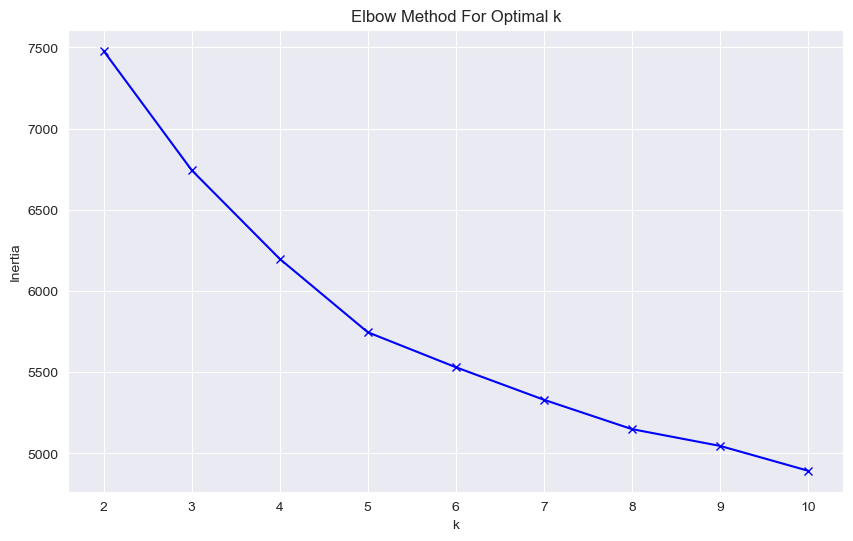

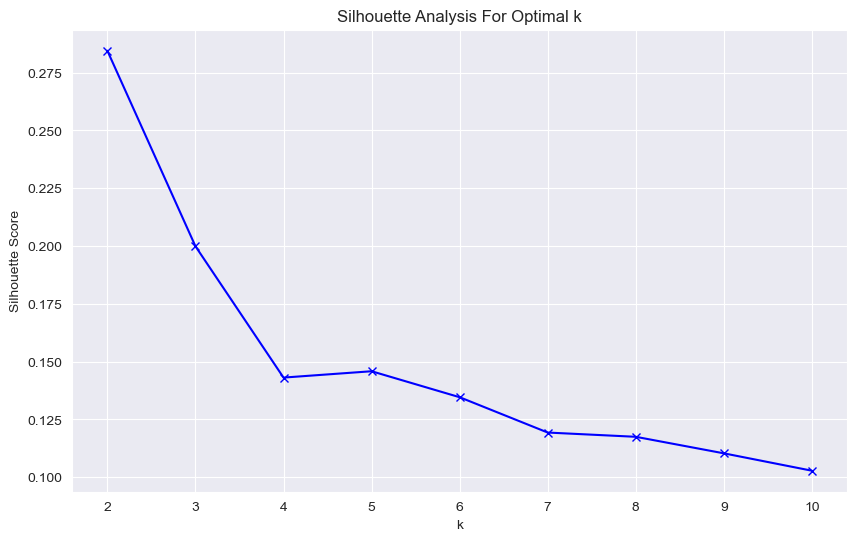

The optimal number of clusters based on silhouette analysis is: 2


In [12]:
# Prepare data for clustering
k_cols = df.select(pl.exclude(['Team', 'Season', 'Rank', 'Playoffs', 'Win', 'Lose', 'PW', 'PL', 'MOV', 'SRS', 'ORtg', 'DRtg'])).columns
X = df.select(k_cols).to_numpy()

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Elbow method
inertias = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K, inertias, 'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()
# Silhouette analysis
silhouette_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(10, 6))
plt.plot(K, silhouette_scores, 'bx-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis For Optimal k')
plt.show()

# Print the best k value based on silhouette score
best_k = K[np.argmax(silhouette_scores)]
print(f"The optimal number of clusters based on silhouette analysis is: {best_k}")

In [13]:
  k_cols

['SOS',
 'NRtg',
 'Pace',
 'FTr',
 '3PAr',
 'TS%',
 'eFG%_O4',
 'TOV%_O4',
 'ORB%_O4',
 'FT/FGA_O4',
 'eFG%_D4',
 'TOV%_D4',
 'DRB%_D4',
 'FT/FGA_D4',
 'Age']

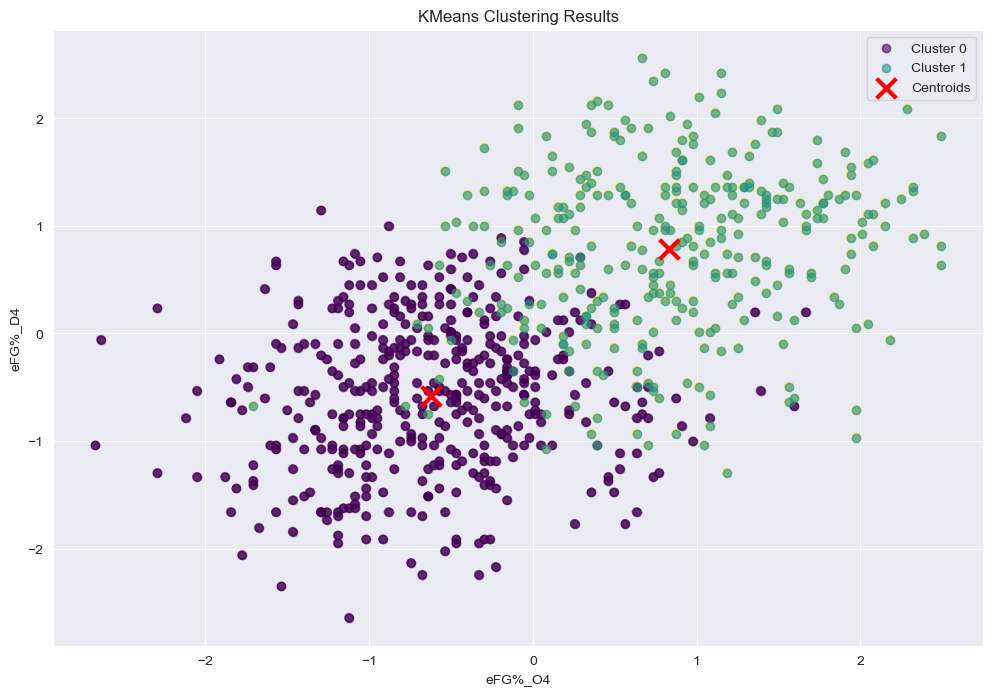


Cluster Centers:
Cluster 0: eFG%_O4=-0.62, eFG%_D4=-0.58
Cluster 1: eFG%_O4=0.83, eFG%_D4=0.78


In [14]:
# Fit KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_scaled)

# Get cluster assignments
cluster_labels = kmeans.labels_

# Create scatter plot
f1 = 6
f2 = 10
plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_scaled[:, f1], X_scaled[:, f2], c=cluster_labels, cmap='viridis', alpha=0.6)

# Create scatter plot with individual labels for clusters
for i in range(2):
    mask = cluster_labels == i
    plt.scatter(X_scaled[mask, f1], X_scaled[mask, f2], c=[plt.cm.viridis(i / 2.)], alpha=0.6, label=f'Cluster {i}')

plt.scatter(kmeans.cluster_centers_[:, f1], kmeans.cluster_centers_[:, f2],
            c='red', marker='x', s=200, linewidth=3, label='Centroids')

# Add labels and title
plt.xlabel(k_cols[f1])
plt.ylabel(k_cols[f2])
plt.title('KMeans Clustering Results')
plt.legend()
plt.show()

# Print cluster centers
print("\nCluster Centers:")
for i, center in enumerate(kmeans.cluster_centers_):
    print(f"Cluster {i}: {k_cols[f1]}={center[f1]:.2f}, {k_cols[f2]}={center[f2]:.2f}")


Second, a random forest analysis is used along with statistical tests to validate feature importance found between the different modeling methods.

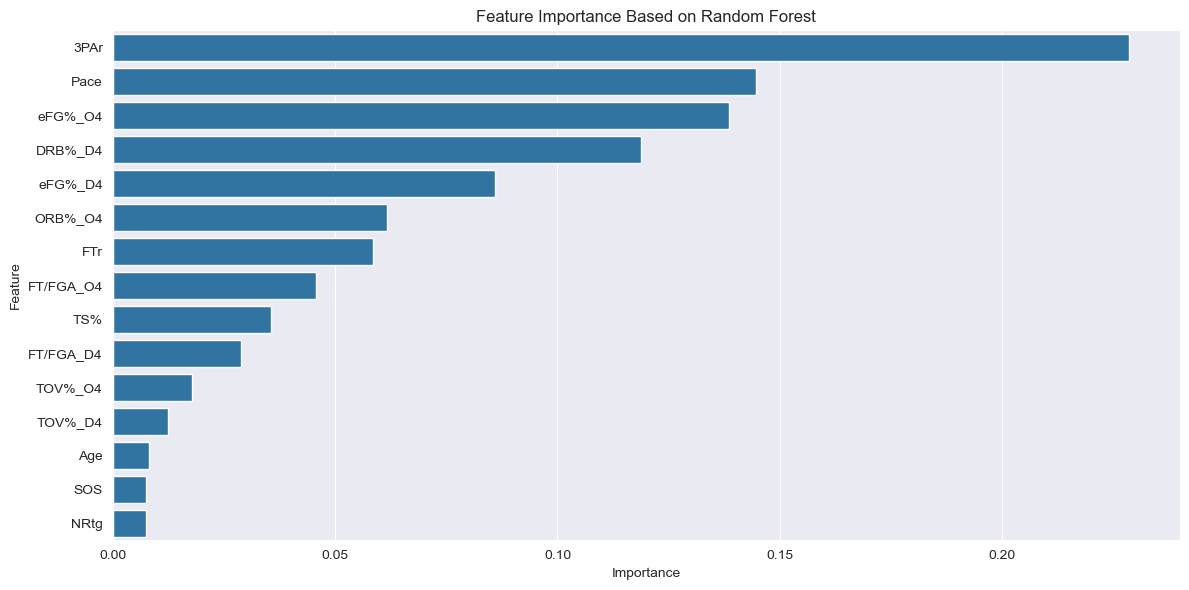


Random Forest Feature Importance:


,Feature,Importance
4,3PAr,0.228525
2,Pace,0.144583
6,eFG%_O4,0.138512
12,DRB%_D4,0.118829
10,eFG%_D4,0.085854
8,ORB%_O4,0.061661
3,FTr,0.058607
9,FT/FGA_O4,0.045714
5,TS%,0.035583
13,FT/FGA_D4,0.028846



Cluster Centers Analysis:


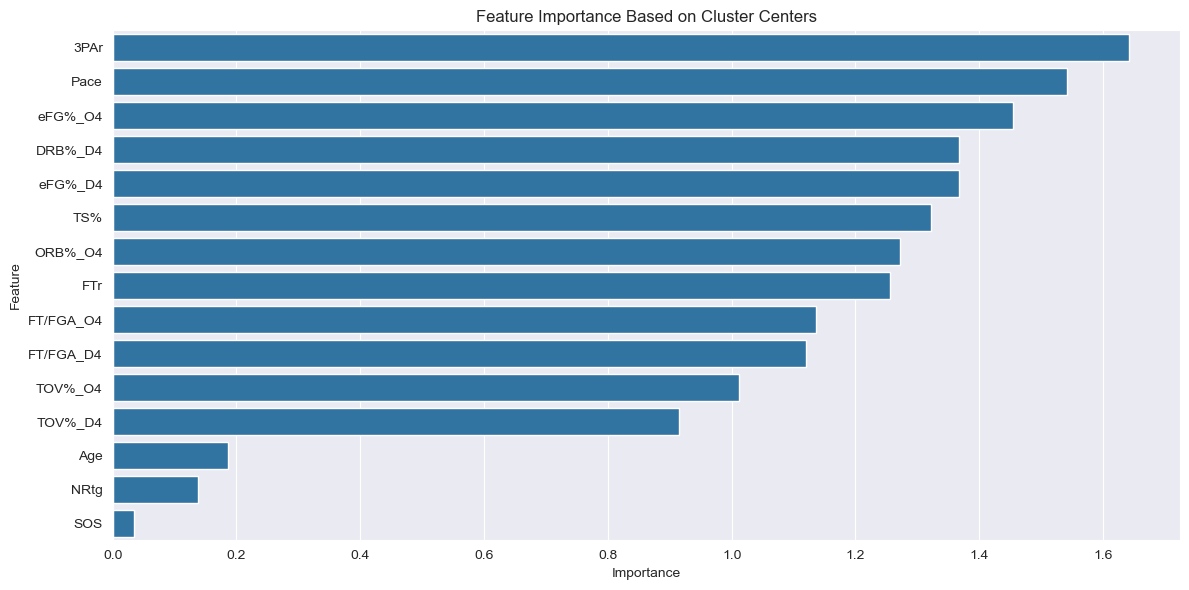

,Feature,Importance
4,3PAr,1.642117
2,Pace,1.542115
6,eFG%_O4,1.454443
12,DRB%_D4,1.367690
10,eFG%_D4,1.367412
5,TS%,1.322448
8,ORB%_O4,1.272024
3,FTr,1.255882
9,FT/FGA_O4,1.136167
13,FT/FGA_D4,1.120401



T-test Analysis:


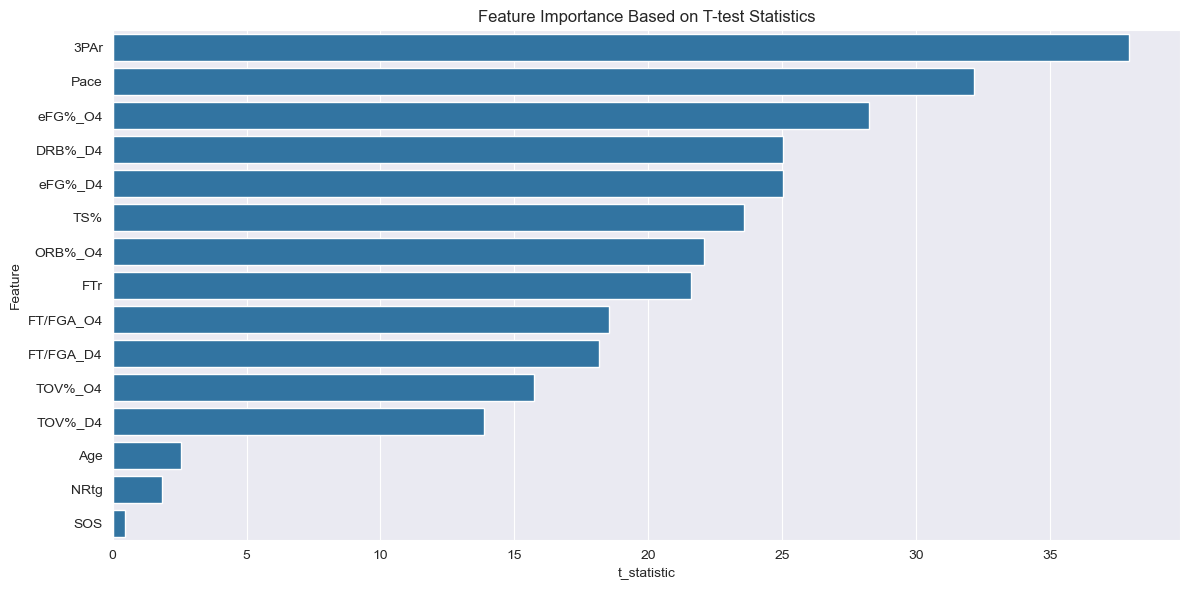

,Feature,t_statistic,p_value
4,3PAr,37.959102,3.259720e-176
2,Pace,32.159245,6.517388e-143
6,eFG%_O4,28.240026,8.294818e-120
12,DRB%_D4,25.047319,6.901697e-101
10,eFG%_D4,25.037935,7.841891e-101
5,TS%,23.580561,3.037651e-92
8,ORB%_O4,22.072825,1.941147e-83
3,FTr,21.614972,8.706318e-81
9,FT/FGA_O4,18.526895,2.668839e-63
13,FT/FGA_D4,18.154763,2.975379e-61


In [15]:
# Analyze cluster centers
def analyze_cluster_centers(X_scaled, cluster_labels, feature_names):
    centers = np.array([X_scaled[cluster_labels == i].mean(axis=0) for i in range(2)])
    diff = np.abs(centers[0] - centers[1])
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': diff
    }).sort_values('Importance', ascending=False)

    plt.figure(figsize=(12, 6))
    sns.barplot(data=importance_df, x='Importance', y='Feature')
    plt.title('Feature Importance Based on Cluster Centers')
    plt.tight_layout()
    plt.show()
    return importance_df


# Perform t-tests between clusters
def analyze_ttest(X_scaled, cluster_labels, feature_names):
    t_stats = []
    p_values = []
    for i in range(X_scaled.shape[1]):
        t_stat, p_val = stats.ttest_ind(
            X_scaled[cluster_labels == 0, i],
            X_scaled[cluster_labels == 1, i]
        )
        t_stats.append(abs(t_stat))
        p_values.append(p_val)

    ttest_df = pd.DataFrame({
        'Feature': feature_names,
        't_statistic': t_stats,
        'p_value': p_values
    }).sort_values('t_statistic', ascending=False)

    plt.figure(figsize=(12, 6))
    sns.barplot(data=ttest_df, x='t_statistic', y='Feature')
    plt.title('Feature Importance Based on T-test Statistics')
    plt.tight_layout()
    plt.show()
    return ttest_df


# Random Forest feature importance
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, cluster_labels)

rf_importance = pd.DataFrame({
    'Feature': k_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=rf_importance, x='Importance', y='Feature')
plt.title('Feature Importance Based on Random Forest')
plt.tight_layout()
plt.show()

print("\nRandom Forest Feature Importance:")
display(rf_importance)

# Print results from all methods
print("\nCluster Centers Analysis:")
display(analyze_cluster_centers(X_scaled, cluster_labels, k_cols))

print("\nT-test Analysis:")
display(analyze_ttest(X_scaled, cluster_labels, k_cols))


**Insights:** In each case, 3PAr and Pace rise to the top followed by some of the more relevant "four factors" features like shooting and rebounding. Interestingly, turnovers do not rank as high as rebounds even though the original assessment of the "four factors" considers turnovers to be more impactful.

To further validate our univariate assumption about 3PAr and Pace, we can plot their averages across the seasons to assess any noteable changes within the time series. As we can see, after the 2010 season, both metrics increase considerably. This marks the often mentioned changes in the game in which teams focus more on 3 point shooting and a higher number of possessions / FGAs. We can assume this might be why rebounds and turnovers are flipped in their "four factor" relevance to success; longer range shooting replaces the threat of turnovers while driving the paint.

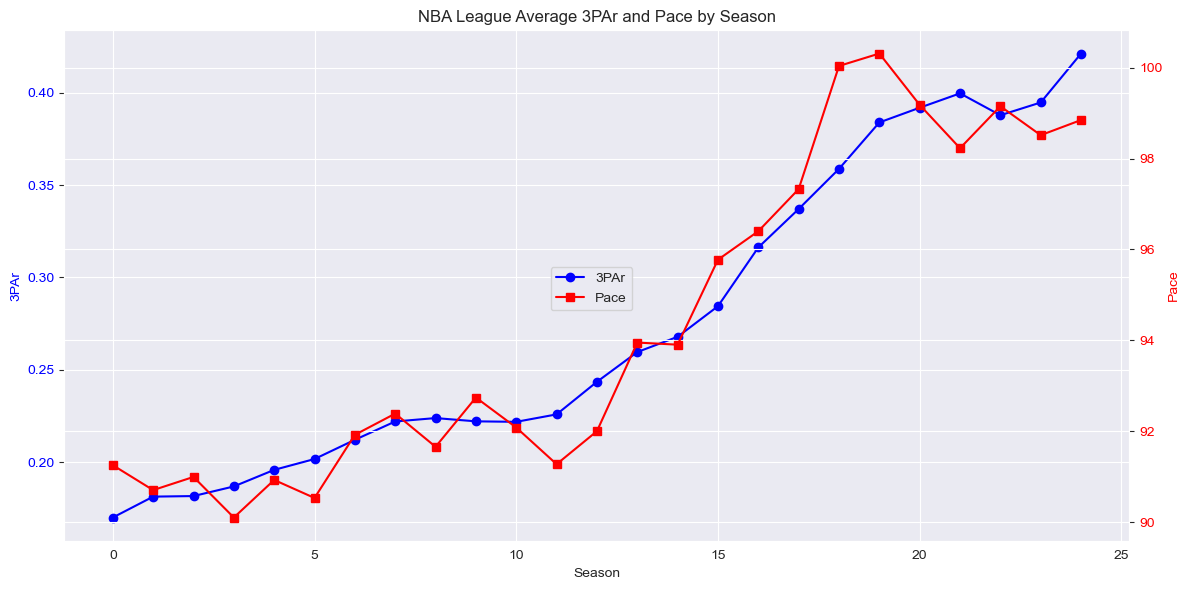

In [16]:
# Calculate average 3PAr and Pace by Season
season_avg = df.group_by('Season').agg(
    mean_3PAr=pl.col('3PAr').mean(),
    mean_pace=pl.col('Pace').mean()
).to_pandas()

# Create figure with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Plot 3PAr
line1 = ax1.plot(season_avg.index, season_avg['mean_3PAr'],
                 color='blue', marker='o', label='3PAr')
ax1.set_xlabel('Season')
ax1.set_ylabel('3PAr', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot Pace  
line2 = ax2.plot(season_avg.index, season_avg['mean_pace'],
                 color='red', marker='s', label='Pace')
ax2.set_ylabel('Pace', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', bbox_to_anchor=(0.45, 0.55),frameon=True)

plt.title('NBA League Average 3PAr and Pace by Season')
plt.tight_layout()
plt.show()


**Insights:** Finally, we can plot a correlation matrix of features among the top six discovered during multivariate analysis. This reduces the set to 3PAr, Pace, eFG%, and O/DRB% as key features which contribute to team success, albeit in the NBA as it stands over the last 25 years. In further modeling player performance, individual statistics supporting these team performance indicators may have more relevance than others.

Additionally, this analysis does not provide conclusive evidence that contextual weights for features like SOS have enough support for model application given our current data.

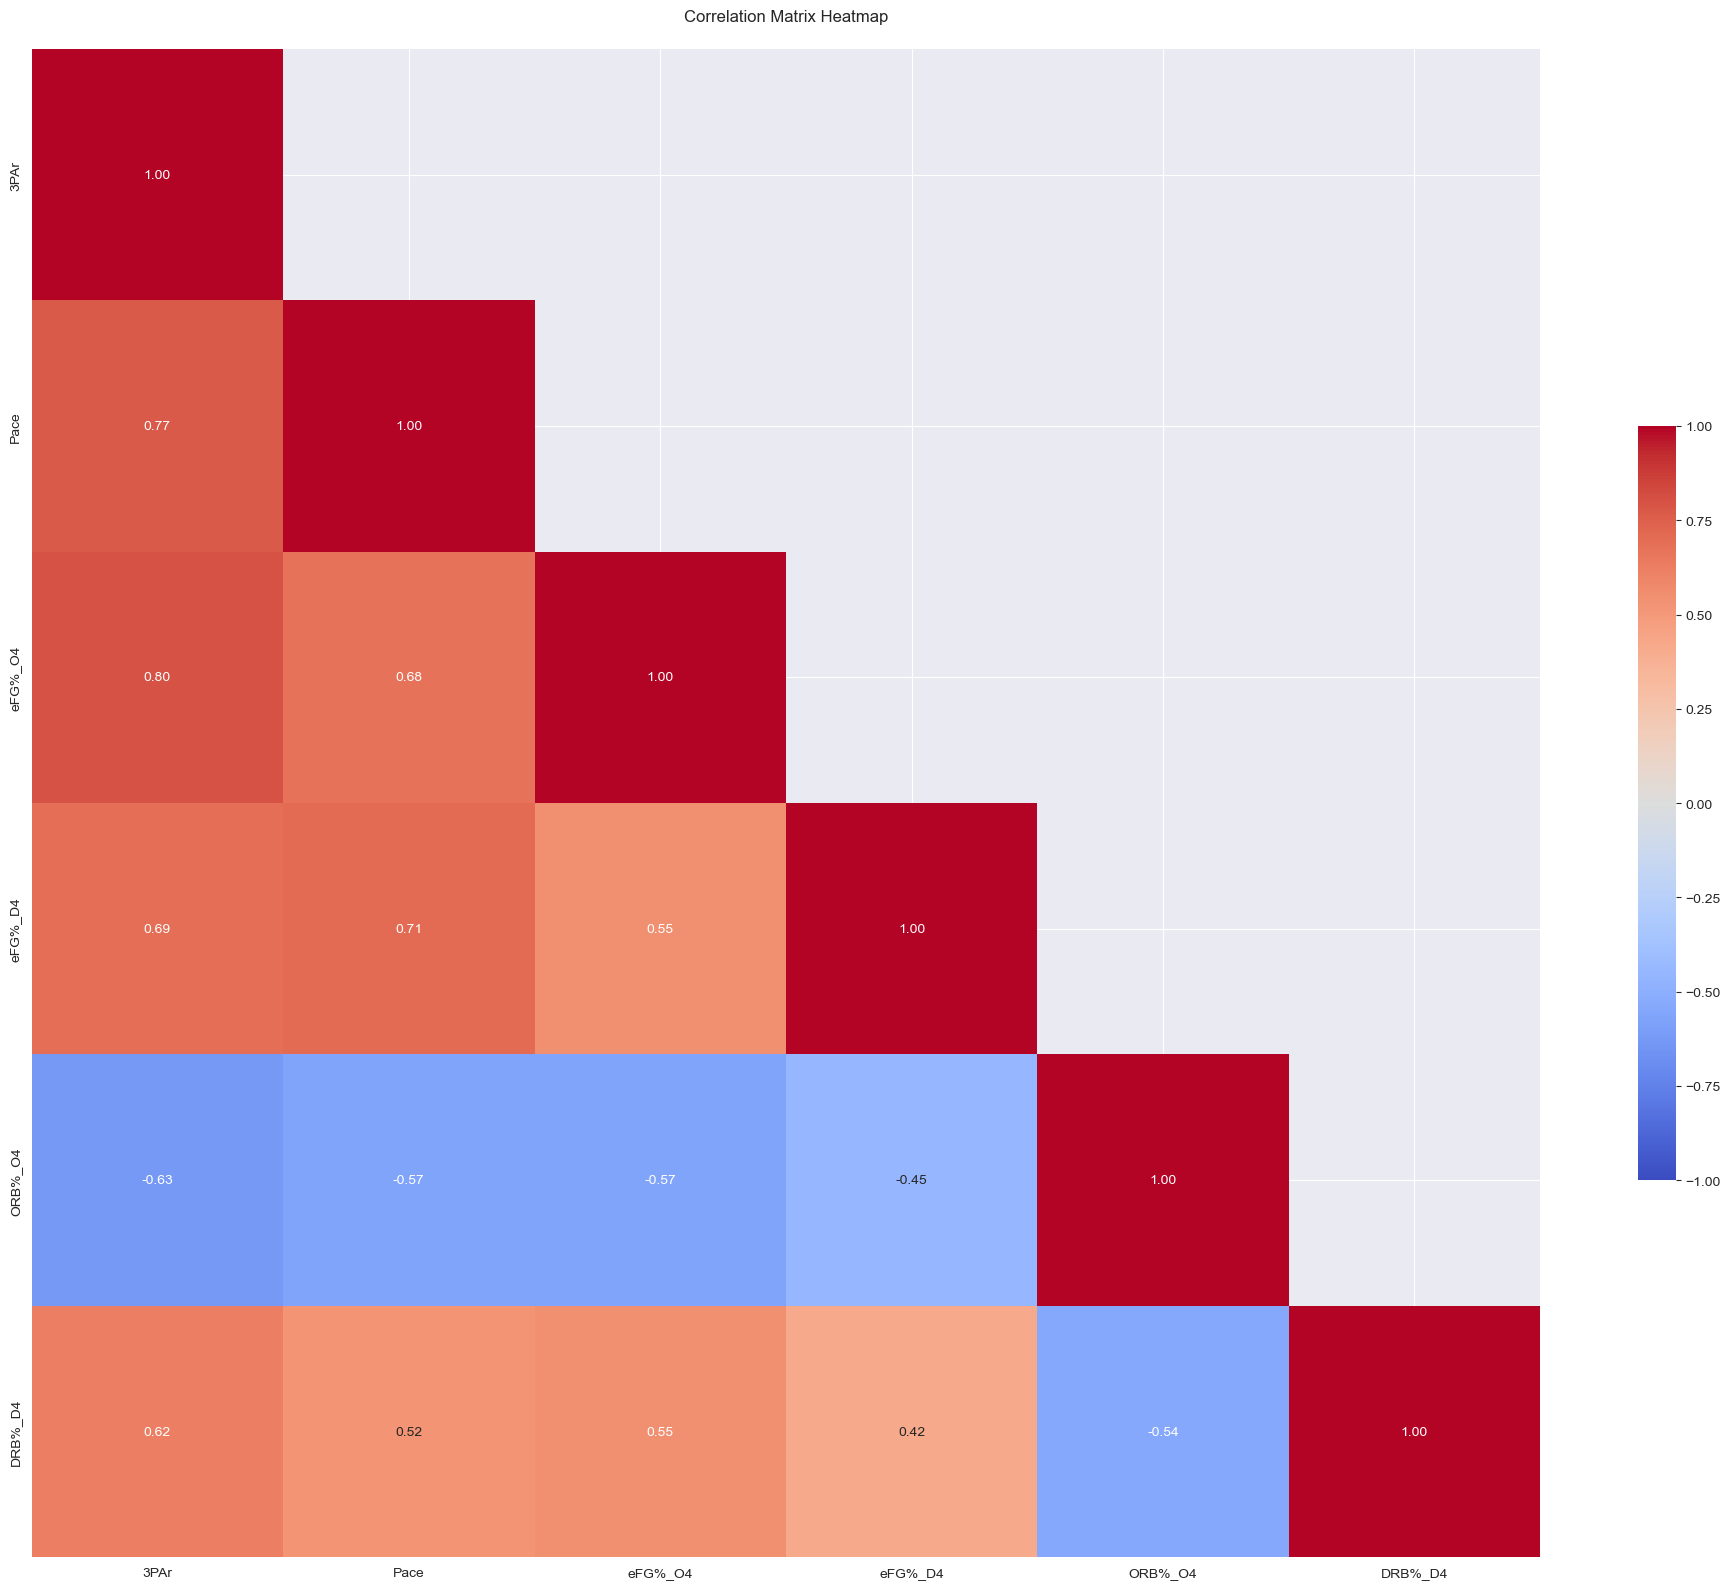

In [17]:
# Create correlation matrix
plt.figure(figsize=(20, 16))
corr_matrix = df.select(['3PAr', 'Pace', 'eFG%_O4', 'eFG%_D4', 'ORB%_O4', 'DRB%_D4']).corr()

# Create heatmap
mask = np.triu(np.ones_like(corr_matrix), k=1)
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            xticklabels=corr_matrix.columns,
            yticklabels=corr_matrix.columns,
            square=True,
            center=0,
            vmin=-1,
            vmax=1,
            cbar_kws={"shrink": .5})

plt.title('Correlation Matrix Heatmap', pad=20)
plt.tight_layout()
plt.show()